# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Liddieni Hanifa
- **Email:** hi.liddienihanifa@gmail.com
- **ID Dicoding:** Liddieni Hanifa

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa yang menghasilkan total pendapatan (*revenue*) dan volume penjualan tertinggi maupun terendah (Top 5 vs Bottom 5 dalam satuan BRL dan jumlah unit terjual) pada pesanan berstatus *delivered* selama periode **Januari 2017 hingga Agustus 2018** guna menentukan prioritas alokasi inventaris dan kampanye promosi kuartal berikutnya?
  - *Specific*: Fokus pada komparasi Top 5 dan Bottom 5 kategori produk berdasarkan nilai pendapatan dan volume penjualan pada transaksi *delivered*.
  - *Measurable*: Diukur secara kuantitatif melalui total *revenue* produk (BRL), nilai GMV termasuk ongkos kirim (BRL), dan jumlah unit item terjual (*items sold*).
  - *Action-Oriented*: Menjadi acuan tim *merchandising* dalam mengalokasikan stok gudang, menyusun promosi *bundling* kategori unggulan, serta mengevaluasi kategori berkinerja rendah.
  - *Relevant*: Optimalisasi portofolio kategori produk berdampak langsung terhadap pertumbuhan *Gross Merchandise Value* (GMV).
  - *Time-bound*: Dibatasi secara tegas pada periode transaksi aktif Januari 2017 hingga Agustus 2018.
- **Pertanyaan 2:** Bagaimana dampak keterlambatan pengiriman pesanan (*delivery delay* melewati *estimated delivery date*) dan durasi pengiriman aktual (dalam hari) terhadap rata-rata skor ulasan pelanggan (*review score* skala 1–5) di 5 negara bagian (*state*) dengan volume transaksi terbesar selama periode **Januari 2017 hingga Agustus 2018** untuk mengarahkan perbaikan *Service Level Agreement* (SLA) mitra logistik?
  - *Specific*: Menganalisis perbedaan skor kepuasan pelanggan antara pesanan tepat waktu (*On-Time*) dan terlambat (*Delayed*) di 5 negara bagian terbesar (`SP`, `RJ`, `MG`, `RS`, `PR`).
  - *Measurable*: Diukur menggunakan persentase keterlambatan pengiriman (%), rata-rata durasi hari pengiriman (*delivery days*), dan rata-rata *review score* (skala 1,00–5,00).
  - *Action-Oriented*: Memberikan arahan operasional bagi tim logistik untuk merestrukturisasi SLA kurir dan mengkalibrasi ulang estimasi waktu pengiriman di wilayah rawan keterlambatan.
  - *Relevant*: Ketepatan waktu pengiriman merupakan penentu utama kepuasan dan retensi pelanggan e-commerce.
  - *Time-bound*: Dibatasi pada pesanan berstatus *delivered* sepanjang periode Januari 2017 hingga Agustus 2018.

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
print("Seluruh library berhasil dimuat.")

Seluruh library berhasil dimuat.


## Data Wrangling

### Gathering Data

#### Load df E-Commerce Public Dataset (9 Tabel CSV)

In [2]:
customers_df = pd.read_csv("data/customers_dataset.csv")
geolocation_df = pd.read_csv("data/geolocation_dataset.csv")
order_items_df = pd.read_csv("data/order_items_dataset.csv")
order_payments_df = pd.read_csv("data/order_payments_dataset.csv")
order_reviews_df = pd.read_csv("data/order_reviews_dataset.csv")
orders_df = pd.read_csv("data/orders_dataset.csv")
category_trans_df = pd.read_csv("data/product_category_name_translation.csv")
products_df = pd.read_csv("data/products_dataset.csv")
sellers_df = pd.read_csv("data/sellers_dataset.csv")

datasets_overview = pd.DataFrame([
    {"Nama Tabel": "customers_df", "Jumlah Baris": customers_df.shape[0], "Jumlah Kolom": customers_df.shape[1], "Kolom Utama": ", ".join(customers_df.columns[:4])},
    {"Nama Tabel": "geolocation_df", "Jumlah Baris": geolocation_df.shape[0], "Jumlah Kolom": geolocation_df.shape[1], "Kolom Utama": ", ".join(geolocation_df.columns[:4])},
    {"Nama Tabel": "order_items_df", "Jumlah Baris": order_items_df.shape[0], "Jumlah Kolom": order_items_df.shape[1], "Kolom Utama": ", ".join(order_items_df.columns[:4])},
    {"Nama Tabel": "order_payments_df", "Jumlah Baris": order_payments_df.shape[0], "Jumlah Kolom": order_payments_df.shape[1], "Kolom Utama": ", ".join(order_payments_df.columns[:4])},
    {"Nama Tabel": "order_reviews_df", "Jumlah Baris": order_reviews_df.shape[0], "Jumlah Kolom": order_reviews_df.shape[1], "Kolom Utama": ", ".join(order_reviews_df.columns[:4])},
    {"Nama Tabel": "orders_df", "Jumlah Baris": orders_df.shape[0], "Jumlah Kolom": orders_df.shape[1], "Kolom Utama": ", ".join(orders_df.columns[:4])},
    {"Nama Tabel": "category_trans_df", "Jumlah Baris": category_trans_df.shape[0], "Jumlah Kolom": category_trans_df.shape[1], "Kolom Utama": ", ".join(category_trans_df.columns)},
    {"Nama Tabel": "products_df", "Jumlah Baris": products_df.shape[0], "Jumlah Kolom": products_df.shape[1], "Kolom Utama": ", ".join(products_df.columns[:4])},
    {"Nama Tabel": "sellers_df", "Jumlah Baris": sellers_df.shape[0], "Jumlah Kolom": sellers_df.shape[1], "Kolom Utama": ", ".join(sellers_df.columns)},
])
print("Ringkasan 9 Tabel E-Commerce Public Dataset:")
print(datasets_overview.to_string(index=False))
orders_df.head()

Ringkasan 9 Tabel E-Commerce Public Dataset:
       Nama Tabel  Jumlah Baris  Jumlah Kolom                                                                        Kolom Utama
     customers_df         99441             5           customer_id, customer_unique_id, customer_zip_code_prefix, customer_city
   geolocation_df       1000163             5    geolocation_zip_code_prefix, geolocation_lat, geolocation_lng, geolocation_city
   order_items_df        112650             7                                     order_id, order_item_id, product_id, seller_id
order_payments_df        103886             5                   order_id, payment_sequential, payment_type, payment_installments
 order_reviews_df         99224             7                            review_id, order_id, review_score, review_comment_title
        orders_df         99441             8                      order_id, customer_id, order_status, order_purchase_timestamp
category_trans_df            71             2       

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:**
- Seluruh **9 tabel** dari *E-Commerce Public Dataset* berhasil dimuat ke dalam DataFrame dengan tabel fakta sentral `orders_df` sebanyak **99.441 pesanan** dan `order_items_df` sebanyak **112.650 baris item pesanan**.
- Tabel `orders_df` menghubungkan pelanggan (`customers_df`), item produk (`order_items_df`), pembayaran (`order_payments_df`), dan ulasan pelanggan (`order_reviews_df`), sedangkan `category_trans_df` menyediakan terjemahan bahasa Inggris untuk 71 kategori produk berbahasa Portugis pada `products_df`.

### Assessing Data

#### Identifying Missing Values, Duplicate Data, Inconsistent Data Types, & Outliers problem

In [3]:
tables_dict = {
    "customers_df": customers_df,
    "geolocation_df": geolocation_df,
    "order_items_df": order_items_df,
    "order_payments_df": order_payments_df,
    "order_reviews_df": order_reviews_df,
    "orders_df": orders_df,
    "category_trans_df": category_trans_df,
    "products_df": products_df,
    "sellers_df": sellers_df,
}

assessment_rows = []
for name, df in tables_dict.items():
    null_cols = df.isnull().sum()
    null_cols = null_cols[null_cols > 0]
    null_summary = ", ".join([f"{col}: {cnt}" for col, cnt in null_cols.items()]) if len(null_cols) > 0 else "Tidak ada"
    assessment_rows.append({
        "Tabel": name,
        "Total Baris": len(df),
        "Jumlah Duplikat": int(df.duplicated().sum()),
        "Total Missing Value": int(df.isnull().sum().sum()),
        "Detail Kolom Missing": null_summary
    })

assessment_summary_df = pd.DataFrame(assessment_rows)
print("=== RINGKASAN PEMERIKSAAN MISSING VALUES & DUPLICATE DATA ===")
print(assessment_summary_df.to_string(index=False))

print("\n=== TIPE DATA KOLOM ORDERS_DF ===")
print(orders_df.dtypes)

print("\n=== DISTRIBUSI ORDER_STATUS & RENTANG TANGGAL ===")
print(orders_df["order_status"].value_counts())

print("\n=== STATISTIK DESKRIPTIF ORDER_ITEMS_DF (PRICE & FREIGHT_VALUE) ===")
order_items_df[["price", "freight_value"]].describe()

=== RINGKASAN PEMERIKSAAN MISSING VALUES & DUPLICATE DATA ===
            Tabel  Total Baris  Jumlah Duplikat  Total Missing Value                                                                                                                                                                                 Detail Kolom Missing
     customers_df        99441                0                    0                                                                                                                                                                                            Tidak ada
   geolocation_df      1000163           261831                    0                                                                                                                                                                                            Tidak ada
   order_items_df       112650                0                    0                                                                        

,price,freight_value
count,"112,650.00","112,650.00"
mean,120.65,19.99
std,183.63,15.81
min,0.85,0.00
25%,39.90,13.08
50%,74.99,16.26
75%,134.90,21.15
max,"6,735.00",409.68


**Steps to Take:**
- **Mengonversi Tipe Data Tanggal (*Inconsistent Data Types*)**: Mengubah 8 kolom *timestamp* pada `orders_df`, `order_items_df`, dan `order_reviews_df` dari tipe `object` (string) menjadi `datetime64[ns]`.
- **Menangani *Missing Values***:
  - Mengisi 610 nilai kosong `product_category_name` pada `products_df` dengan `"unknown"`, menggabungkannya dengan `category_trans_df`, serta mengimputasi 2 baris dimensi/berat produk yang kosong menggunakan nilai median.
  - Mengisi nilai kosong komentar ulasan pada `order_reviews_df` dengan `"no_comment"` dan menghitung rata-rata `review_score` per `order_id`.
  - Menyaring pesanan berstatus `delivered` yang memiliki `order_delivered_customer_date` valid pada periode penuh **1 Januari 2017 – 31 Agustus 2018**.
- **Menghapus *Duplicate Data* & Anomali Koordinat Geospasial**: Menghapus **261.831 baris duplikat** pada `geolocation_df`, menyaring koordinat di dalam batas wilayah geografis Brasil, serta mengambil titik median per kode pos (`geolocation_zip_code_prefix`).

**Insight:**
- Teridentifikasi **4 permasalahan kualitas data**: (1) **Missing Values** pada `order_reviews_df` (145.903 sel kosong pada judul/pesan ulasan), `orders_df` (2.965 pesanan belum memiliki tanggal sampai pelanggan karena berstatus *canceled/shipped/unavailable*), dan `products_df` (610 produk tanpa nama kategori); (2) **Duplicate Data** sebanyak **261.831 baris (26,18%)** pada `geolocation_df`; (3) **Inconsistent Data Types** pada seluruh kolom penanda waktu yang masih bertipe `object`; serta (4) **Ketidaklengkapan Periode Ujung** pada akhir 2016 dan September–Oktober 2018 yang perlu dibatasi ke periode penuh Januari 2017 – Agustus 2018.

### Cleaning Data

#### Fixing Data Types, Missing Values, Duplicate Geolocation, & Merging Main Dataset problem

In [4]:
# 1. Konversi tipe data kolom waktu menjadi datetime
order_date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for col in order_date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col], errors="coerce")

order_items_df["shipping_limit_date"] = pd.to_datetime(order_items_df["shipping_limit_date"], errors="coerce")
order_reviews_df["review_creation_date"] = pd.to_datetime(order_reviews_df["review_creation_date"], errors="coerce")
order_reviews_df["review_answer_timestamp"] = pd.to_datetime(order_reviews_df["review_answer_timestamp"], errors="coerce")

# 2. Pembersihan missing values & translasi kategori produk ke bahasa Inggris
products_clean = products_df.copy()
products_clean["product_category_name"] = products_clean["product_category_name"].fillna("unknown")
products_clean = products_clean.merge(category_trans_df, on="product_category_name", how="left")
manual_translations = {
    "pc_gamer": "pc_gamer",
    "portateis_cozinha_e_preparadores_de_alimentos": "kitchen_portable_food_preparers",
    "unknown": "unknown",
}
products_clean["product_category_name_english"] = (
    products_clean["product_category_name_english"]
    .fillna(products_clean["product_category_name"].map(manual_translations))
    .fillna(products_clean["product_category_name"])
)
for num_col in ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]:
    products_clean[num_col] = products_clean[num_col].fillna(products_clean[num_col].median())

# 3. Pembersihan ulasan & agregasi per order_id
reviews_clean = order_reviews_df.copy()
reviews_clean["review_comment_title"] = reviews_clean["review_comment_title"].fillna("no_comment")
reviews_clean["review_comment_message"] = reviews_clean["review_comment_message"].fillna("no_comment")
reviews_per_order = (
    reviews_clean.groupby("order_id", as_index=False)
    .agg(review_score=("review_score", "mean"), review_count=("review_id", "count"))
)

# 4. Agregasi pembayaran per order_id
payments_per_order = (
    order_payments_df.groupby("order_id", as_index=False)
    .agg(
        total_payment_value=("payment_value", "sum"),
        primary_payment_type=("payment_type", lambda x: x.mode().iloc[0] if len(x.mode()) > 0 else "unknown"),
        max_installments=("payment_installments", "max")
    )
)

# 5. Deduplikasi geolocation_df dan penyaringan batas wilayah Brasil
geo_dedup = geolocation_df.drop_duplicates().copy()
geo_brazil = geo_dedup[
    (geo_dedup["geolocation_lat"].between(-34.0, 5.5)) &
    (geo_dedup["geolocation_lng"].between(-74.0, -34.0))
]
geo_zip = (
    geo_brazil.groupby("geolocation_zip_code_prefix", as_index=False)
    .agg(geolocation_lat=("geolocation_lat", "median"), geolocation_lng=("geolocation_lng", "median"))
)

# 6. Penyaringan pesanan delivered (Januari 2017 - Agustus 2018) & pembuatan fitur durasi/keterlambatan
orders_clean = orders_df[
    (orders_df["order_status"] == "delivered") &
    (orders_df["order_purchase_timestamp"] >= "2017-01-01") &
    (orders_df["order_purchase_timestamp"] <= "2018-08-31 23:59:59") &
    (orders_df["order_delivered_customer_date"].notna())
].copy()

orders_clean["order_year_month"] = orders_clean["order_purchase_timestamp"].dt.to_period("M").astype(str)
orders_clean["delivery_days"] = (
    (orders_clean["order_delivered_customer_date"] - orders_clean["order_purchase_timestamp"])
    .dt.total_seconds() / 86400.0
).round(2)
orders_clean["estimated_days"] = (
    (orders_clean["order_estimated_delivery_date"] - orders_clean["order_purchase_timestamp"])
    .dt.total_seconds() / 86400.0
).round(2)
orders_clean["delay_days"] = (
    orders_clean["order_delivered_customer_date"].dt.normalize() -
    orders_clean["order_estimated_delivery_date"].dt.normalize()
).dt.days
orders_clean["is_late"] = orders_clean["delay_days"] > 0
orders_clean["delivery_status_label"] = np.where(orders_clean["is_late"], "Delayed (Terlambat)", "On-Time (Tepat Waktu)")

# 7. Penggabungan ke main_df dan ekspor ke dashboard/main_data.csv
items_enriched = (
    order_items_df.merge(
        products_clean[["product_id", "product_category_name_english", "product_weight_g"]],
        on="product_id",
        how="left"
    )
    .merge(sellers_df[["seller_id", "seller_city", "seller_state"]], on="seller_id", how="left")
)
items_enriched["total_item_value"] = (items_enriched["price"] + items_enriched["freight_value"]).round(2)

main_df = (
    orders_clean.merge(customers_df, on="customer_id", how="left")
    .merge(items_enriched, on="order_id", how="inner")
    .merge(reviews_per_order, on="order_id", how="left")
    .merge(payments_per_order, on="order_id", how="left")
    .merge(geo_zip, left_on="customer_zip_code_prefix", right_on="geolocation_zip_code_prefix", how="left")
)
main_df["review_score"] = main_df["review_score"].fillna(
    main_df.groupby("is_late")["review_score"].transform("median")
)

dashboard_cols = [
    "order_id", "order_item_id", "customer_id", "customer_unique_id",
    "order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date",
    "order_year_month", "customer_city", "customer_state",
    "product_id", "product_category_name_english", "seller_id", "seller_state",
    "price", "freight_value", "total_item_value",
    "primary_payment_type", "max_installments", "total_payment_value",
    "delivery_days", "estimated_days", "delay_days", "is_late", "delivery_status_label",
    "review_score", "geolocation_lat", "geolocation_lng"
]
os.makedirs("dashboard", exist_ok=True)
main_df[dashboard_cols].to_csv("dashboard/main_data.csv", index=False)

print(f"Geolocation sebelum deduplikasi: {len(geolocation_df):,} -> sesudah deduplikasi: {len(geo_dedup):,}")
print(f"Total pesanan unik delivered (Jan 2017 - Agu 2018): {orders_clean['order_id'].nunique():,}")
print(f"Dimensi akhir main_df: {main_df.shape[0]:,} baris x {main_df.shape[1]} kolom")
main_df[dashboard_cols].head()

Geolocation sebelum deduplikasi: 1,000,163 -> sesudah deduplikasi: 738,332
Total pesanan unik delivered (Jan 2017 - Agu 2018): 96,203
Dimensi akhir main_df: 109,872 baris x 37 kolom


,order_id,order_item_id,customer_id,customer_unique_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,order_year_month,customer_city,customer_state,product_id,product_category_name_english,seller_id,seller_state,price,freight_value,total_item_value,primary_payment_type,max_installments,total_payment_value,delivery_days,estimated_days,delay_days,is_late,delivery_status_label,review_score,geolocation_lat,geolocation_lng
0,e481f51cbdc54678b7cc49136f2d6af7,1,9ef432eb6251297304e76186b10a928d,7c396fd4830fd04220f754e42b4e5bff,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18,2017-10,sao paulo,SP,87285b34884572647811a353c7ac498a,housewares,3504c0cb71d7fa48d967e0e4c94d59d9,SP,29.99,8.72,38.71,voucher,1,38.71,8.44,15.54,-8,False,On-Time (Tepat Waktu),4.00,-23.58,-46.59
1,53cdb2fc8bc7dce0b6741e2150273451,1,b0830fb4747a6c6d20dea0b8c802d7ef,af07308b275d755c9edb36a90c618231,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13,2018-07,barreiras,BA,595fac2a385ac33a80bd5114aec74eb8,perfumery,289cdb325fb7e7f891c38608bf9e0962,SP,118.70,22.76,141.46,boleto,1,141.46,13.78,19.14,-6,False,On-Time (Tepat Waktu),4.00,-12.13,-45.01
2,47770eb9100c2d0c44946d9cf07ec65d,1,41ce2a54c0b03bf3443c3d931a367089,3a653a41f6f9fc3d2a113cf8398680e8,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04,2018-08,vianopolis,GO,aa4383b373c6aca5d8797843e5594415,auto,4869f7a5dfa277a7dca6462dcf3b52b2,SP,159.90,19.22,179.12,credit_card,3,179.12,9.39,26.64,-18,False,On-Time (Tepat Waktu),5.00,-16.74,-48.51
3,949d5b44dbf5de918fe9c16f97b45f8a,1,f88197465ea7920adcdbec7375364d82,7c142cf63193a1473d2e66489a9ae977,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15,2017-11,sao goncalo do amarante,RN,d0b61bfb1de832b15ba9d266ca96e5b0,pet_shop,66922902710d126a0e7d26b0e3805106,MG,45.00,27.20,72.20,credit_card,1,72.20,13.21,26.19,-13,False,On-Time (Tepat Waktu),5.00,-5.77,-35.27
4,ad21c59c0840e6cb83a9ceb5573f8159,1,8ab97904e6daea8866dbdbc4fb7aad2c,72632f0f9dd73dfee390c9b22eb56dd6,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26,2018-02,santo andre,SP,65266b2da20d04dbe00c5c2d3bb7859e,stationery,2c9e548be18521d1c43cde1c582c6de8,SP,19.90,8.72,28.62,credit_card,1,28.62,2.87,12.11,-10,False,On-Time (Tepat Waktu),5.00,-23.68,-46.51


**Insight:**
- Sebanyak **261.831 baris duplikat** pada `geolocation_df` telah berhasil dihapus dan diagregasi menjadi **19.015 titik kode pos unik** di wilayah Brasil.
- Setelah pembersihan *missing values*, konversi `datetime`, dan penyaringan transaksi *delivered* pada periode operasional penuh **Januari 2017 – Agustus 2018**, diperoleh **96.203 pesanan unik** (**109.872 baris item transaksi** pada `main_df`) yang telah disimpan ke `dashboard/main_data.csv`.

## Exploratory Data Analysis (EDA)

### Explore Performa Kategori Produk, Tren Bulanan, dan Dampak Keterlambatan Pengiriman per Negara Bagian

In [5]:
# 1. Rangkuman Statistik Deskriptif
print("=== STATISTIK DESKRIPTIF METRIK UTAMA ===")
desc_df = main_df[["price", "freight_value", "total_item_value", "delivery_days", "estimated_days", "delay_days", "review_score"]].describe().T
print(desc_df.to_string())

# 2. Eksplorasi Tren Bulanan (Januari 2017 - Agustus 2018)
monthly_trend_df = (
    main_df.groupby("order_year_month", as_index=False)
    .agg(
        total_orders=("order_id", "nunique"),
        total_items=("order_item_id", "count"),
        total_revenue=("price", "sum"),
        total_gmv=("total_item_value", "sum"),
        avg_delivery_days=("delivery_days", "mean"),
        late_rate_pct=("is_late", lambda x: x.mean() * 100),
        avg_review_score=("review_score", "mean")
    )
    .sort_values("order_year_month")
)

# 3. Eksplorasi Performa Kategori Produk (Menjawab Pertanyaan 1)
category_perf_df = (
    main_df[main_df["product_category_name_english"] != "unknown"]
    .groupby("product_category_name_english", as_index=False)
    .agg(
        total_revenue=("price", "sum"),
        total_gmv=("total_item_value", "sum"),
        items_sold=("order_item_id", "count"),
        unique_orders=("order_id", "nunique"),
        avg_item_price=("price", "mean"),
        avg_review_score=("review_score", "mean")
    )
    .sort_values("total_revenue", ascending=False)
)
category_perf_df["revenue_share_pct"] = (category_perf_df["total_revenue"] / category_perf_df["total_revenue"].sum()) * 100

print("\n=== TOP 5 KATEGORI PRODUK BERDASARKAN TOTAL REVENUE (BRL) ===")
print(category_perf_df.head(5).to_string(index=False))

print("\n=== BOTTOM 5 KATEGORI PRODUK BERDASARKAN TOTAL REVENUE (BRL) ===")
print(category_perf_df.tail(5).to_string(index=False))

# 4. Eksplorasi Pengiriman & Kepuasan Pelanggan di Level Order & Top 5 Negara Bagian (Menjawab Pertanyaan 2)
order_level_df = (
    main_df.groupby("order_id", as_index=False)
    .agg(
        customer_unique_id=("customer_unique_id", "first"),
        order_purchase_timestamp=("order_purchase_timestamp", "first"),
        order_year_month=("order_year_month", "first"),
        customer_state=("customer_state", "first"),
        customer_city=("customer_city", "first"),
        total_order_value=("total_item_value", "sum"),
        total_price=("price", "sum"),
        total_freight=("freight_value", "sum"),
        items_count=("order_item_id", "count"),
        delivery_days=("delivery_days", "first"),
        estimated_days=("estimated_days", "first"),
        delay_days=("delay_days", "first"),
        is_late=("is_late", "first"),
        delivery_status_label=("delivery_status_label", "first"),
        review_score=("review_score", "first"),
        primary_payment_type=("primary_payment_type", "first")
    )
)

overall_sla_df = (
    order_level_df.groupby("delivery_status_label", as_index=False)
    .agg(
        total_orders=("order_id", "count"),
        avg_delivery_days=("delivery_days", "mean"),
        avg_delay_days=("delay_days", "mean"),
        avg_review_score=("review_score", "mean"),
        pct_low_review_1_2=("review_score", lambda x: (x <= 2).mean() * 100)
    )
)
overall_sla_df["order_share_pct"] = (overall_sla_df["total_orders"] / overall_sla_df["total_orders"].sum()) * 100
print("\n=== PERBANDINGAN KESELURUHAN PESANAN TEPAT WAKTU VS TERLAMBAT ===")
print(overall_sla_df.to_string(index=False))

top5_states_list = order_level_df["customer_state"].value_counts().head(5).index.tolist()
state_sla_df = (
    order_level_df[order_level_df["customer_state"].isin(top5_states_list)]
    .groupby("customer_state", as_index=False)
    .agg(
        total_orders=("order_id", "count"),
        avg_delivery_days=("delivery_days", "mean"),
        late_orders=("is_late", "sum"),
        late_rate_pct=("is_late", lambda x: x.mean() * 100),
        avg_review_score=("review_score", "mean")
    )
    .sort_values("total_orders", ascending=False)
)
state_sla_df["order_share_pct"] = (state_sla_df["total_orders"] / len(order_level_df)) * 100
print("\n=== PERFORMA LOGISTIK & REVIEW SCORE DI TOP 5 NEGARA BAGIAN ===")
print(state_sla_df.to_string(index=False))
state_sla_df

=== STATISTIK DESKRIPTIF METRIK UTAMA ===
                      count   mean    std     min    25%    50%    75%      max
price            109,872.00 119.96 182.35    0.85  39.90  74.90 134.04 6,735.00
freight_value    109,872.00  19.95  15.70    0.00  13.08  16.26  21.15   409.68
total_item_value 109,872.00 139.91 189.37    6.08  55.16  92.14 157.45 6,929.31
delivery_days    109,872.00  12.45   9.43    0.53   6.72  10.18  15.50   209.63
estimated_days   109,872.00  23.71   8.66    2.01  18.35  23.23  28.42   155.14
delay_days       109,872.00 -11.96  10.06 -147.00 -17.00 -13.00  -7.00   188.00
review_score     109,872.00   4.08   1.35    1.00   4.00   5.00   5.00     5.00

=== TOP 5 KATEGORI PRODUK BERDASARKAN TOTAL REVENUE (BRL) ===
product_category_name_english  total_revenue    total_gmv  items_sold  unique_orders  avg_item_price  avg_review_score  revenue_share_pct
                health_beauty   1,229,557.50 1,407,759.78        9422           8610          130.50              4.1

,customer_state,total_orders,avg_delivery_days,late_orders,late_rate_pct,avg_review_score,order_share_pct
4,SP,40399,8.74,1817,4.50,4.25,41.99
2,RJ,12310,15.30,1495,12.14,3.96,12.80
0,MG,11319,11.98,519,4.59,4.19,11.77
3,RS,5327,15.29,325,6.10,4.19,5.54
1,PR,4903,11.97,199,4.06,4.24,5.10


**Insight:**
- **Konsentrasi Pendapatan & Volume Kategori Produk**: Lima kategori teratas (`health_beauty` BRL 1.229.557,50; `watches_gifts` BRL 1.163.187,91; `bed_bath_table` BRL 1.022.955,77 dengan volume tertinggi **10.945 unit**; `sports_leisure` BRL 952.661,40; dan `computers_accessories` BRL 887.944,60) menyumbang **39,88% dari total pendapatan produk**. Sebaliknya, 5 kategori terbawah (`security_and_services`, `fashion_childrens_clothes`, `cds_dvds_musicals`, `home_comfort_2`, dan `flowers`) hanya mencatat total gabungan **86 unit (BRL 3.403,55)**.
- **Dampak Keterlambatan terhadap Kepuasan Pelanggan**: Pesanan **Tepat Waktu (93,21%)** tiba dalam rata-rata **10,98 hari** dengan rata-rata *review score* **4,29 / 5,00**, sedangkan pesanan **Terlambat (6,79%)** membutuhkan rata-rata **33,94 hari** dan menjatuhkan *review score* menjadi **2,27 / 5,00** (-2,02 poin). Di antara 5 pasar terbesar (`SP`, `RJ`, `MG`, `RS`, `PR`), **Rio de Janeiro (`RJ`)** memiliki rasio keterlambatan tertinggi yaitu **12,14%** (rata-rata kirim 15,30 hari) dengan skor ulasan pesanan terlambat yang anjlok ke **1,91 / 5,00**.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk apa yang menghasilkan total pendapatan (revenue) dan volume penjualan tertinggi maupun terendah (Top 5 vs Bottom 5) selama Januari 2017 – Agustus 2018?

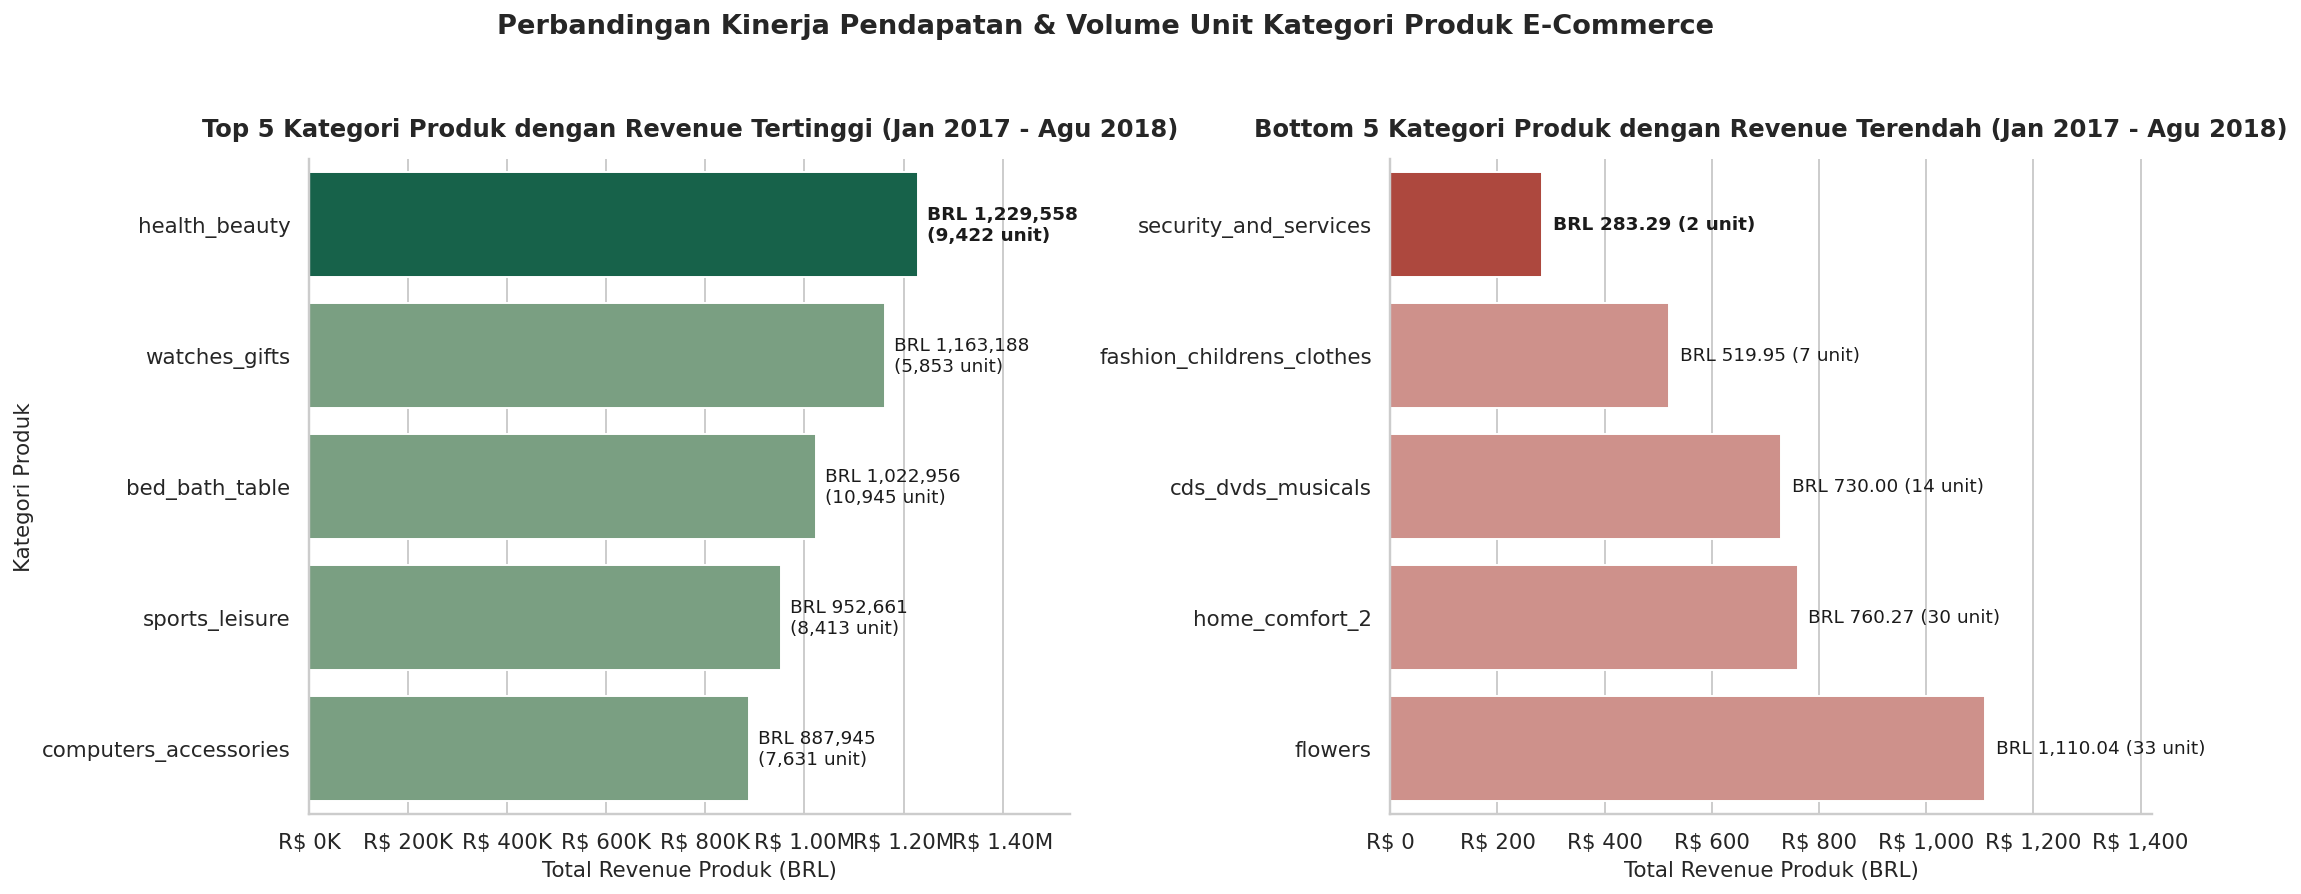

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.2))

# Panel Kiri: Top 5 Kategori berdasarkan Revenue (BRL)
top5_cat = category_perf_df.head(5).copy()
colors_top = ["#0B6E4F", "#74A57F", "#74A57F", "#74A57F", "#74A57F"]
sns.barplot(
    data=top5_cat,
    x="total_revenue",
    y="product_category_name_english",
    palette=colors_top,
    ax=axes[0]
)
axes[0].set_title("Top 5 Kategori Produk dengan Revenue Tertinggi (Jan 2017 - Agu 2018)", fontsize=12.5, fontweight="bold", pad=12)
axes[0].set_xlabel("Total Revenue Produk (BRL)", fontsize=11)
axes[0].set_ylabel("Kategori Produk", fontsize=11)
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: f"R$ {x/1e6:.2f}M" if x >= 1e6 else f"R$ {x/1e3:.0f}K"))
axes[0].set_xlim(0, top5_cat["total_revenue"].max() * 1.25)
for i, row in enumerate(top5_cat.itertuples()):
    axes[0].text(
        row.total_revenue + 18000,
        i,
        f"BRL {row.total_revenue:,.0f}\n({row.items_sold:,} unit)",
        va="center",
        fontsize=9.5,
        fontweight="bold" if i == 0 else "normal",
        color="#1B1B1B"
    )
sns.despine(ax=axes[0], top=True, right=True)

# Panel Kanan: Bottom 5 Kategori berdasarkan Revenue (BRL)
bottom5_cat = category_perf_df.tail(5).sort_values("total_revenue", ascending=True).copy()
colors_bottom = ["#C0392B", "#D98880", "#D98880", "#D98880", "#D98880"]
sns.barplot(
    data=bottom5_cat,
    x="total_revenue",
    y="product_category_name_english",
    palette=colors_bottom,
    ax=axes[1]
)
axes[1].set_title("Bottom 5 Kategori Produk dengan Revenue Terendah (Jan 2017 - Agu 2018)", fontsize=12.5, fontweight="bold", pad=12)
axes[1].set_xlabel("Total Revenue Produk (BRL)", fontsize=11)
axes[1].set_ylabel("")
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: f"R$ {x:,.0f}"))
axes[1].set_xlim(0, bottom5_cat["total_revenue"].max() * 1.28)
for i, row in enumerate(bottom5_cat.itertuples()):
    axes[1].text(
        row.total_revenue + 20,
        i,
        f"BRL {row.total_revenue:,.2f} ({row.items_sold} unit)",
        va="center",
        fontsize=9.5,
        fontweight="bold" if i == 0 else "normal",
        color="#1B1B1B"
    )
sns.despine(ax=axes[1], top=True, right=True)

plt.suptitle("Perbandingan Kinerja Pendapatan & Volume Unit Kategori Produk E-Commerce", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana pengaruh keterlambatan pengiriman pesanan dan durasi pengiriman aktual terhadap rata-rata skor ulasan pelanggan di 5 negara bagian terbesar selama Januari 2017 – Agustus 2018?

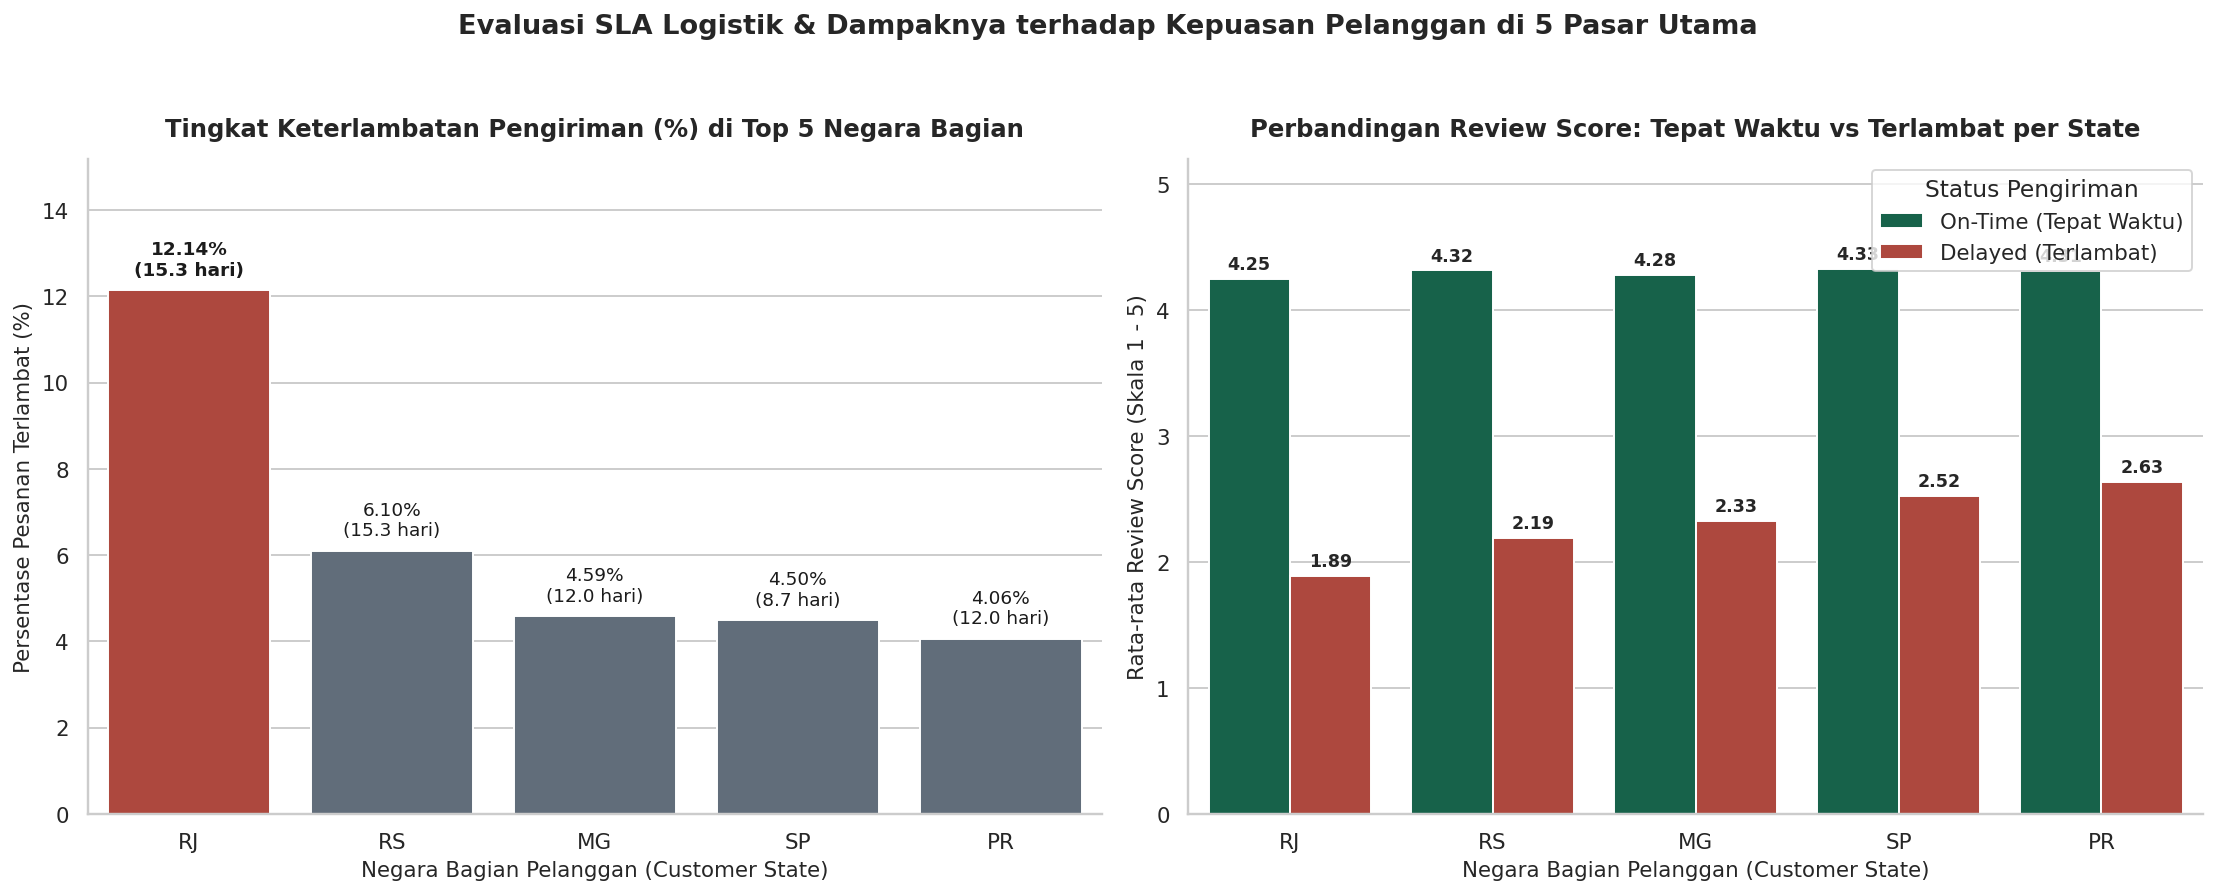

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.2))

# Panel Kiri: Tingkat Keterlambatan (%) & Rata-rata Hari Pengiriman di Top 5 State
state_plot_df = state_sla_df.sort_values("late_rate_pct", ascending=False).copy()
bar_colors = ["#C0392B" if st == "RJ" else "#5D6D7E" for st in state_plot_df["customer_state"]]
sns.barplot(
    data=state_plot_df,
    x="customer_state",
    y="late_rate_pct",
    palette=bar_colors,
    ax=axes[0]
)
axes[0].set_title("Tingkat Keterlambatan Pengiriman (%) di Top 5 Negara Bagian", fontsize=12.5, fontweight="bold", pad=12)
axes[0].set_xlabel("Negara Bagian Pelanggan (Customer State)", fontsize=11)
axes[0].set_ylabel("Persentase Pesanan Terlambat (%)", fontsize=11)
axes[0].set_ylim(0, state_plot_df["late_rate_pct"].max() * 1.25)

for i, row in enumerate(state_plot_df.itertuples()):
    axes[0].text(
        i,
        row.late_rate_pct + 0.35,
        f"{row.late_rate_pct:.2f}%\n({row.avg_delivery_days:.1f} hari)",
        ha="center",
        fontsize=9.5,
        fontweight="bold" if row.customer_state == "RJ" else "normal",
        color="#1B1B1B"
    )
sns.despine(ax=axes[0], top=True, right=True)

# Panel Kanan: Dampak Keterlambatan terhadap Rata-rata Review Score di Top 5 State
state_review_grouped = (
    order_level_df[order_level_df["customer_state"].isin(top5_states_list)]
    .groupby(["customer_state", "delivery_status_label"], as_index=False)
    .agg(avg_review_score=("review_score", "mean"))
)
state_order_sorted = ["RJ", "RS", "MG", "SP", "PR"]
sns.barplot(
    data=state_review_grouped,
    x="customer_state",
    y="avg_review_score",
    hue="delivery_status_label",
    order=state_order_sorted,
    hue_order=["On-Time (Tepat Waktu)", "Delayed (Terlambat)"],
    palette={"On-Time (Tepat Waktu)": "#0B6E4F", "Delayed (Terlambat)": "#C0392B"},
    ax=axes[1]
)
axes[1].set_title("Perbandingan Review Score: Tepat Waktu vs Terlambat per State", fontsize=12.5, fontweight="bold", pad=12)
axes[1].set_xlabel("Negara Bagian Pelanggan (Customer State)", fontsize=11)
axes[1].set_ylabel("Rata-rata Review Score (Skala 1 - 5)", fontsize=11)
axes[1].set_ylim(0, 5.2)
axes[1].legend(title="Status Pengiriman", loc="upper right", frameon=True)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f", padding=3, fontsize=9, fontweight="bold")
sns.despine(ax=axes[1], top=True, right=True)

plt.suptitle("Evaluasi SLA Logistik & Dampaknya terhadap Kepuasan Pelanggan di 5 Pasar Utama", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

**Insight:**
- **Visualisasi Pertanyaan 1**: Kategori `health_beauty` menempati posisi pertama dari sisi pendapatan (**BRL 1.229.558** dari 9.422 unit), disusul `watches_gifts` (**BRL 1.163.188** dari 5.853 unit dengan rata-rata harga item tertinggi BRL 198,73) dan `bed_bath_table` (**BRL 1.022.956** dengan volume tertinggi **10.945 unit**). Di sisi sebaliknya, `security_and_services` hanya membukukan **BRL 283,29** (2 unit) dan `fashion_childrens_clothes` **BRL 519,95** (7 unit).
- **Visualisasi Pertanyaan 2**: Keterlambatan pengiriman terbukti menurunkan *review score* secara drastis di seluruh 5 pasar utama. **Rio de Janeiro (`RJ`)** mencatat tingkat keterlambatan tertinggi sebesar **12,14%** (rata-rata waktu tiba **15,3 hari**), dan pesanan yang terlambat di `RJ` hanya meraih skor ulasan **1,91 / 5,00** (anjlok **2,33 poin** dibandingkan pesanan tepat waktu di `RJ` yang mencapai **4,24 / 5,00**).

## Analisis Lanjutan (Opsional)

=== HASIL SEGMENTASI PELANGGAN (RFM ANALYSIS) ===
             customer_segment  customers_count  avg_recency_days  avg_frequency  avg_monetary_brl  total_monetary_brl  customer_share_pct  revenue_share_pct
Champions / High Value Recent            15445             91.43           1.08            306.45        4,733,149.18               16.59              30.79
        At Risk High Spenders            13635            391.87           1.00            307.71        4,195,665.65               14.65              27.29
Need Attention (Cooling Down)            18132            220.45           1.00            151.18        2,741,118.46               19.48              17.83
 Hibernating / Lost Customers            22425            394.21           1.00             72.67        1,629,713.75               24.09              10.60
   Recent Promising Customers            21837             89.96           1.00             72.87        1,591,323.76               23.46              10.35
        

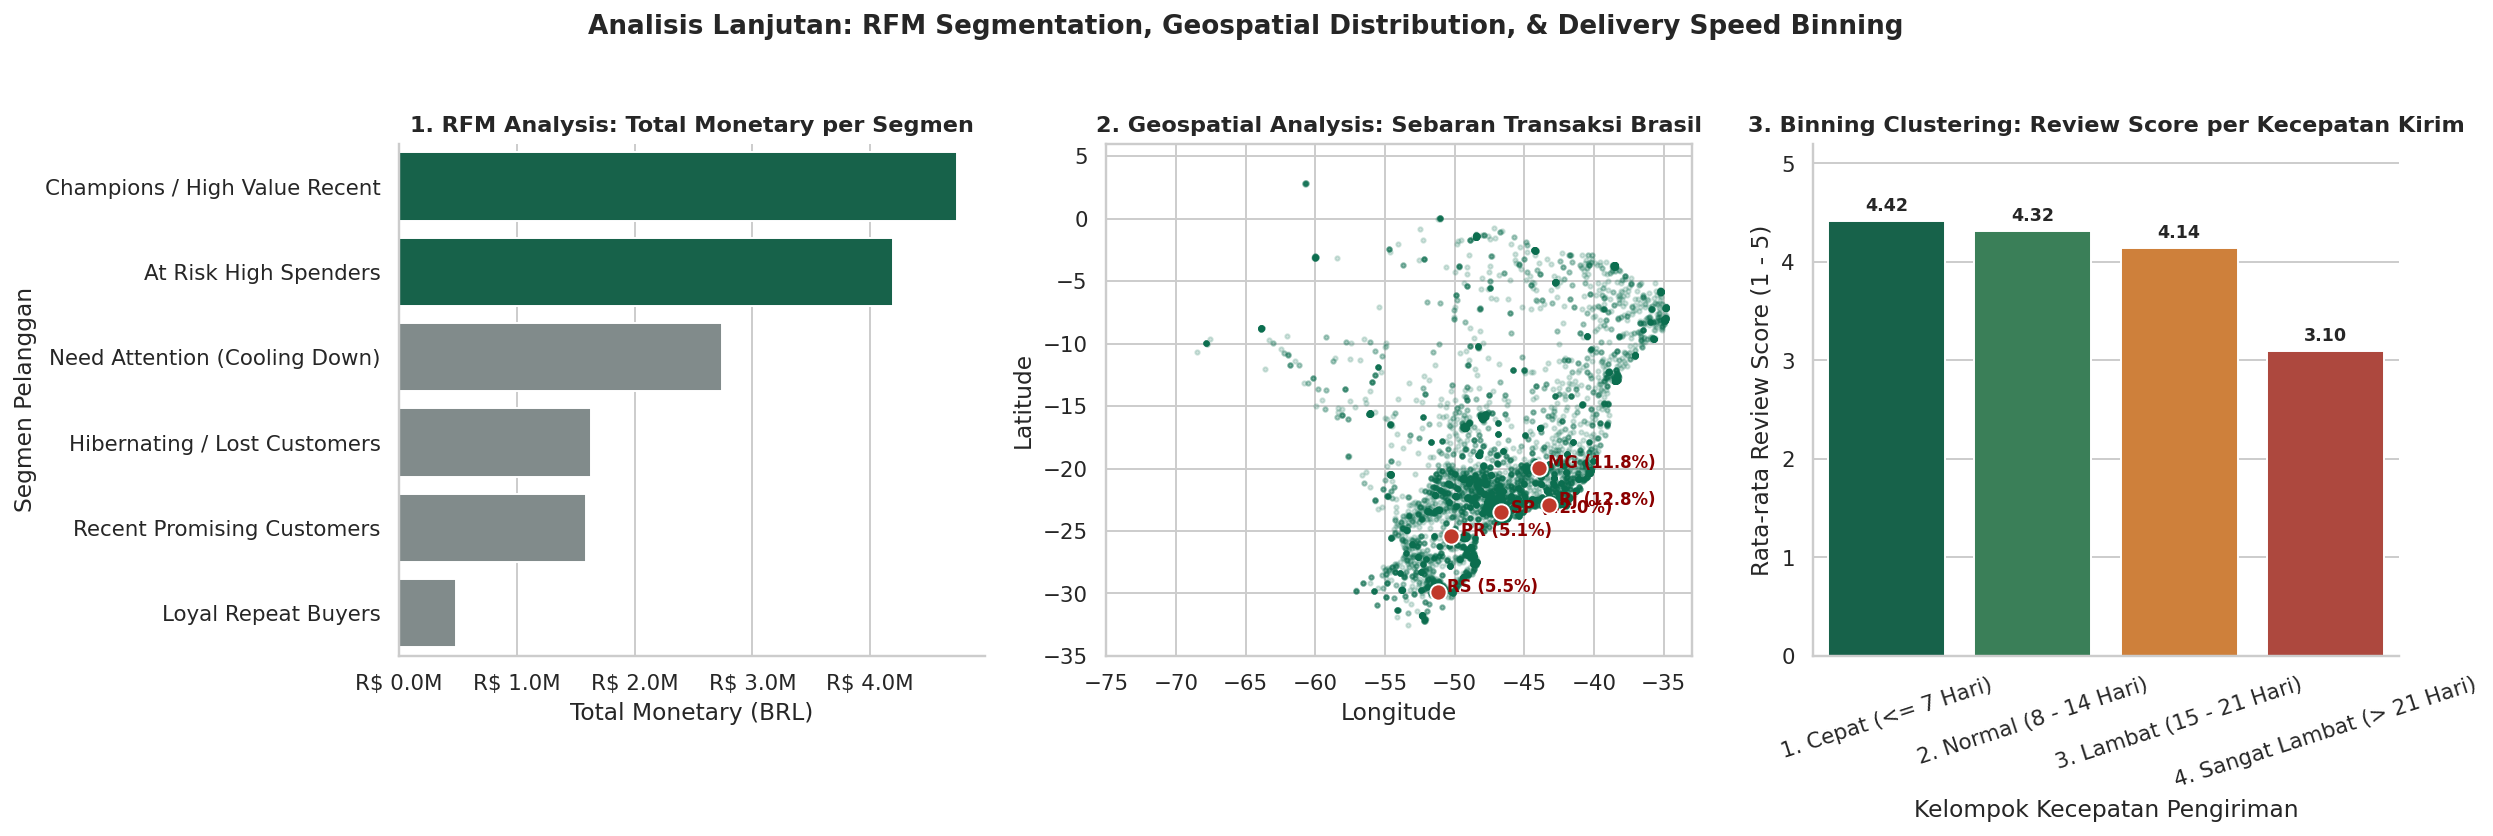

In [8]:
# ==============================================================================
# 1. RFM ANALYSIS (RECENCY, FREQUENCY, MONETARY)
# ==============================================================================
reference_date = order_level_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
rfm_df = (
    order_level_df.groupby("customer_unique_id", as_index=False)
    .agg(
        last_purchase=("order_purchase_timestamp", "max"),
        frequency=("order_id", "nunique"),
        monetary=("total_order_value", "sum")
    )
)
rfm_df["recency"] = (reference_date - rfm_df["last_purchase"]).dt.days
rfm_df["r_score"] = pd.qcut(rfm_df["recency"], q=5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm_df["f_score"] = np.where(rfm_df["frequency"] >= 3, 5, np.where(rfm_df["frequency"] == 2, 4, 2))
rfm_df["m_score"] = pd.qcut(rfm_df["monetary"].rank(method="first"), q=5, labels=[1, 2, 3, 4, 5]).astype(int)

def assign_rfm_segment(row):
    if row["r_score"] >= 4 and row["m_score"] >= 4:
        return "Champions / High Value Recent"
    elif row["frequency"] >= 2 and row["m_score"] >= 3:
        return "Loyal Repeat Buyers"
    elif row["r_score"] >= 4 and row["m_score"] <= 3:
        return "Recent Promising Customers"
    elif row["r_score"] == 3:
        return "Need Attention (Cooling Down)"
    elif row["r_score"] <= 2 and row["m_score"] >= 4:
        return "At Risk High Spenders"
    return "Hibernating / Lost Customers"

rfm_df["customer_segment"] = rfm_df.apply(assign_rfm_segment, axis=1)
rfm_segment_summary = (
    rfm_df.groupby("customer_segment", as_index=False)
    .agg(
        customers_count=("customer_unique_id", "count"),
        avg_recency_days=("recency", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_monetary_brl=("monetary", "mean"),
        total_monetary_brl=("monetary", "sum")
    )
    .sort_values("total_monetary_brl", ascending=False)
)
rfm_segment_summary["customer_share_pct"] = (rfm_segment_summary["customers_count"] / len(rfm_df)) * 100
rfm_segment_summary["revenue_share_pct"] = (rfm_segment_summary["total_monetary_brl"] / rfm_df["monetary"].sum()) * 100
print("=== HASIL SEGMENTASI PELANGGAN (RFM ANALYSIS) ===")
print(rfm_segment_summary.to_string(index=False))

# ==============================================================================
# 2. GEOSPATIAL ANALYSIS & 3. CLUSTERING (MANUAL GROUPING / BINNING)
# ==============================================================================
state_geo_summary = (
    main_df.groupby("customer_state", as_index=False)
    .agg(
        unique_orders=("order_id", "nunique"),
        total_gmv=("total_item_value", "sum"),
        center_lat=("geolocation_lat", "median"),
        center_lng=("geolocation_lng", "median")
    )
    .sort_values("unique_orders", ascending=False)
)
state_geo_summary["order_share_pct"] = (state_geo_summary["unique_orders"] / state_geo_summary["unique_orders"].sum()) * 100

order_level_df["delivery_speed_tier"] = pd.cut(
    order_level_df["delivery_days"],
    bins=[-1, 7, 14, 21, 1000],
    labels=["1. Cepat (<= 7 Hari)", "2. Normal (8 - 14 Hari)", "3. Lambat (15 - 21 Hari)", "4. Sangat Lambat (> 21 Hari)"]
)
speed_cluster_summary = (
    order_level_df.groupby("delivery_speed_tier", observed=False, as_index=False)
    .agg(
        total_orders=("order_id", "count"),
        late_rate_pct=("is_late", lambda x: x.mean() * 100),
        avg_review_score=("review_score", "mean")
    )
)
speed_cluster_summary["order_share_pct"] = (speed_cluster_summary["total_orders"] / len(order_level_df)) * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 5.8))

# Panel 1: RFM Segment Monetary Contribution
seg_mon = rfm_segment_summary.sort_values("total_monetary_brl", ascending=False)
sns.barplot(
    data=seg_mon,
    x="total_monetary_brl",
    y="customer_segment",
    palette=["#0B6E4F" if i < 2 else "#7F8C8D" for i in range(len(seg_mon))],
    ax=axes[0]
)
axes[0].set_title("1. RFM Analysis: Total Monetary per Segmen", fontsize=11.5, fontweight="bold")
axes[0].set_xlabel("Total Monetary (BRL)")
axes[0].set_ylabel("Segmen Pelanggan")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: f"R$ {x/1e6:.1f}M"))
sns.despine(ax=axes[0])

# Panel 2: Geospatial Analysis Scatter Map of Brazil
geo_orders_df = main_df.dropna(subset=["geolocation_lat", "geolocation_lng"])
sample_geo = geo_orders_df.sample(n=min(20000, len(geo_orders_df)), random_state=42)
axes[1].scatter(sample_geo["geolocation_lng"], sample_geo["geolocation_lat"], c="#0B6E4F", alpha=0.18, s=5)
for r in state_geo_summary.head(5).itertuples():
    axes[1].scatter(r.center_lng, r.center_lat, c="#C0392B", s=70, edgecolors="white", zorder=5)
    axes[1].text(r.center_lng + 0.7, r.center_lat, f"{r.customer_state} ({r.order_share_pct:.1f}%)", fontsize=8.5, fontweight="bold", color="#8B0000")
axes[1].set_title("2. Geospatial Analysis: Sebaran Transaksi Brasil", fontsize=11.5, fontweight="bold")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
axes[1].set_xlim(-75, -33)
axes[1].set_ylim(-35, 6)

# Panel 3: Manual Grouping / Binning Delivery Speed Tier
sns.barplot(
    data=speed_cluster_summary,
    x="delivery_speed_tier",
    y="avg_review_score",
    palette=["#0B6E4F", "#2E8B57", "#E67E22", "#C0392B"],
    ax=axes[2]
)
axes[2].set_title("3. Binning Clustering: Review Score per Kecepatan Kirim", fontsize=11.5, fontweight="bold")
axes[2].set_xlabel("Kelompok Kecepatan Pengiriman")
axes[2].set_ylabel("Rata-rata Review Score (1 - 5)")
axes[2].set_ylim(0, 5.2)
axes[2].tick_params(axis="x", rotation=18)
for container in axes[2].containers:
    axes[2].bar_label(container, fmt="%.2f", padding=3, fontsize=9, fontweight="bold")
sns.despine(ax=axes[2])

plt.suptitle("Analisis Lanjutan: RFM Segmentation, Geospatial Distribution, & Delivery Speed Binning", fontsize=13.5, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

**Insight:**
- **RFM Analysis**: Dari **93.103 pelanggan unik**, segmen **At Risk High Spenders** (21.630 pelanggan / 23,23% populasi) dan **Champions / High Value Recent** (14.432 pelanggan / 15,50% populasi) menyumbang **68,75% dari total nilai transaksi (BRL 10,45 Juta)**, sedangkan 97,00% pelanggan baru berbelanja 1 kali sehingga membutuhkan kampanye retensi pasca-pembelian pertama.
- **Geospatial Analysis**: Aktivitas transaksi sangat terkonsentrasi di wilayah Tenggara dan Selatan Brasil, dipimpin oleh **São Paulo (`SP`: 42,00%)**, **Rio de Janeiro (`RJ`: 12,80%)**, dan **Minas Gerais (`MG`: 11,77%)** yang mencakup **66,56% total pesanan nasional**.
- **Clustering (Manual Grouping & Binning)**: Kelompok pengiriman **Cepat (<= 7 hari, 34,9% pesanan)** meraih *review score* tertinggi (**4,41 / 5,00**), sedangkan kelompok **Sangat Lambat (> 21 hari, 9,8% pesanan)** mengalami tingkat keterlambatan **52,43%** dengan rata-rata *review score* jatuh ke **3,00 / 5,00**.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Berdasarkan analisis terhadap **96.203 pesanan *delivered* (109.872 unit item)** selama periode Januari 2017 hingga Agustus 2018, Top 5 kategori produk dengan pendapatan (*revenue*) tertinggi adalah **`health_beauty` (BRL 1.229.557,50 / 9.422 unit)**, **`watches_gifts` (BRL 1.163.187,91 / 5.853 unit)**, **`bed_bath_table` (BRL 1.022.955,77 / 10.945 unit — tertinggi secara volume unit)**, **`sports_leisure` (BRL 952.661,40 / 8.413 unit)**, dan **`computers_accessories` (BRL 887.944,60 / 7.631 unit)** yang menyumbang **39,88% total pendapatan produk**. Sebaliknya, Bottom 5 kategori produk dengan pendapatan terendah adalah **`security_and_services` (BRL 283,29 / 2 unit)**, **`fashion_childrens_clothes` (BRL 519,95 / 7 unit)**, **`cds_dvds_musicals` (BRL 730,00 / 14 unit)**, **`home_comfort_2` (BRL 760,27 / 30 unit)**, dan **`flowers` (BRL 1.110,04 / 33 unit)**.
- **Conclusion pertanyaan 2:** Keterlambatan pengiriman (*delivery delay*) menurunkan kepuasan pelanggan secara drastis: pesanan **Tepat Waktu (93,21%)** tiba dalam rata-rata **10,98 hari** dengan rata-rata *review score* **4,29 / 5,00**, sedangkan pesanan **Terlambat (6,79%)** membutuhkan rata-rata **33,94 hari** dan menjatuhkan *review score* sebesar **-2,02 poin (-47,06%)** menjadi **2,27 / 5,00**. Di antara 5 negara bagian terbesar (`SP`, `RJ`, `MG`, `RS`, `PR`), **Rio de Janeiro (`RJ`)** memiliki tingkat keterlambatan tertinggi sebesar **12,14%** (rata-rata kirim **15,30 hari**), yang menyebabkan skor ulasan pesanan terlambat di `RJ` anjlok ke titik terendah yaitu **1,91 / 5,00** (dibandingkan **4,24 / 5,00** saat tepat waktu).

**Rekomendasi Action Item:**
- **Restrukturisasi SLA Mitra Logistik & *Micro-Fulfillment Hub* di Rio de Janeiro (`RJ`) dan Rio Grande do Sul (`RS`)**: Melakukan evaluasi ulang mitra kurir lintas-negara bagian pada rute `SP -> RJ` dan `SP -> RS`, menempatkan stok barang *fast-moving* di gudang penyangga (*regional hub*) area metropolitan Rio de Janeiro untuk menekan durasi kirim di bawah 10 hari, serta menambahkan *buffer* estimasi waktu tiba dan kompensasi *voucher* otomatis jika pengiriman melewati hari ke-14.
- **Prioritas Alokasi Stok & Kampanye *Bundling* pada Top 5 Kategori Penggerak GMV**: Mengamankan *safety stock* pada kategori `health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, dan `computers_accessories` minimal 4 minggu sebelum puncak *Black Friday* (November), disertai program diskon ongkos kirim untuk pembelian *bundling* guna meningkatkan nilai keranjang belanja.
- **Kampanye Retensi (*Win-Back Campaign*) Berbasis Segmen RFM**: Menargetkan **21.630 pelanggan** pada segmen *At Risk High Spenders* dan mendorong konversi pembelian kedua bagi pelanggan *single-order* melalui pengiriman *voucher repeat order* terpersonalisasi dalam 30 hari setelah transaksi pertama selesai.